# 04 · RAG walkthrough (Step 7): company PDFs → answers with sources

**RAG = Retrieval-Augmented Generation.** LLM ko poori company ki policies yaad nahi hoti — aur jo yaad
nahi, wo bana deta hai (hallucination). RAG mein pehle documents se sahi hissa **dhoondte** hain, phir
sirf usi se jawab dete hain, **source ke saath**.

```
question → retrieve top chunks → answer only from them (+ citation)   or   "not found"
```
Code: `src/data/make_company_docs.py`, `src/rag/rag_system.py`, `src/rag/evaluate_rag.py`, `src/rag/ask.py`

In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 110)
sorted(p.name for p in Path("data/docs").glob("*"))

['Customer_Support_SOP.pdf',
 'Pricing_Discounts_and_Plans.pdf',
 'Q3_2026_Business_Review.pdf',
 'Returns_and_Refund_Policy.pdf',
 'Shipping_and_Delivery_Policy.pdf',
 'Warranty_Policy.pdf']

## 1. Ingest: PDF se text
`pypdf` har page ka text nikalta hai. (Scanned PDF ho toh OCR chahiye — pytesseract.)

In [2]:
from src.rag.rag_system import read_document
for page, text in read_document(Path("data/docs/Returns_and_Refund_Policy.pdf")):
    print(f"--- page {page} ---"); print(text[:900])

--- page 1 ---
Returns and Refund Policy
Kaveri Retail Pvt. Ltd. (fictional company used for this project)
RET-01, version 3.2, effective 1 April 2026
1. Purpose
This policy explains when customers can return products, how refunds are paid, and how long each
step takes. It applies to all orders placed on the Kaveri Retail website and app.
2. Return Window by Category
Electronics can be returned within 7 days of delivery. Clothing can be returned within 15 days of
delivery. Furniture can be returned within 10 days of delivery, only if it is unassembled and in original
packaging. Office Supplies can be returned within 30 days of delivery. Items marked 'Final Sale' cannot
be returned. The return window is counted from the delivery date shown in the tracking history.
3. Condition of Returned Items
Products must be unused, with all tags, accessories, manuals and the original box. Electronics must be
factory


## 2. Chunking
Poora document ek saath search karna bekaar hai (jawab ek paragraph mein hota hai). Hum **numbered headings**
par todte hain, lambe sections ko ~120 words ke tukdon mein (overlap ke saath). Har chunk apna
document + section + page yaad rakhta hai → citation.

In [3]:
from src.rag.rag_system import ingest
chunks = ingest()
df = pd.DataFrame([vars(c) for c in chunks]); df["words"] = df.text.str.split().str.len()
print(len(chunks), "chunks"); display(df.groupby("doc").agg(chunks=("text", "size"), avg_words=("words", "mean")).round(0))
df.iloc[3]

42 chunks


,chunks,avg_words
doc,,
Customer_Support_SOP,7,46.0
Pricing_Discounts_and_Plans,7,38.0
Q3_2026_Business_Review,7,41.0
Returns_and_Refund_Policy,8,46.0
Shipping_and_Delivery_Policy,7,37.0
Warranty_Policy,6,37.0


doc                                                                                                 Customer_Support_SOP
section                                                                                             3. Escalation Matrix
page                                                                                                                   1
text       Level 1 agents handle all tickets first. Escalate to a Level 2 specialist if the ticket is not resolved wi...
words                                                                                                                 72
Name: 3, dtype: object

## 3. Retrieval — 5 tareeke
| Method | Idea |
|---|---|
| tfidf | rare words ko zyada weight, cosine similarity |
| bm25 | search engines ka standard (Elasticsearch); lambe chunks ko penalty |
| char | 3-5 letter tukde → typos, Hinglish spellings |
| lsa | TF-IDF → SVD "topics": thoda semantic, poora offline |
| hybrid | teeno ki ranking ko jodna (Reciprocal Rank Fusion) |

In [4]:
from src.rag.rag_system import RETRIEVERS, expand_query
texts = [f"{c.section} {c.text}" for c in chunks]
q = "When will I get my money back if I paid with UPI?"
for name, make in RETRIEVERS.items():
    s = make().fit(texts).scores(q); top = np.argsort(-s)[:3]
    print(f"{name:7s}", " | ".join(f"{chunks[i].doc[:12]}·{chunks[i].section[:22]}" for i in top))

tfidf   Returns_and_·1. Purpose | Returns_and_·3. Condition of Return | Returns_and_·4. Refund Timelines
bm25    Returns_and_·1. Purpose | Returns_and_·3. Condition of Return | Returns_and_·4. Refund Timelines
char    Returns_and_·1. Purpose | Returns_and_·3. Condition of Return | Shipping_and·5. Damaged or Missing 
lsa     Returns_and_·1. Purpose | Returns_and_·3. Condition of Return | Returns_and_·4. Refund Timelines
hybrid  Returns_and_·1. Purpose | Returns_and_·3. Condition of Return | Returns_and_·4. Refund Timelines


Sahi jawab "4. Refund Timelines" mein hai, lekin sawal mein "refund" word hi nahi — "money back" hai.
Word-matching methods "1. Purpose" utha lete hain (usme likha hai "how refunds are paid"). Yahi
**paraphrase problem** hai — iska asli ilaaj embeddings (sentence-transformers) ya LLM query rewriting hai.

## 4. Evaluation — bina test set ke RAG "achha lagta hai", saabit nahi hota
37 sawal (direct, paraphrase, Hinglish, report) + 6 aise sawal jinka jawab documents mein hai hi nahi.

In [5]:
r = json.load(open("reports/rag_metrics.json"))
ret = pd.DataFrame(r["retrieval"]).T.rename(columns={"hit1": "hit@1", "hit3": "hit@3"})
display(ret.sort_values("mrr", ascending=False))
pd.DataFrame(r["hit3_by_kind_with_expansion"]).T

,hit@1,hit@3,mrr
lsa+expand,0.892,0.973,0.924
hybrid+expand,0.892,0.973,0.924
tfidf+expand,0.892,0.973,0.924
hybrid,0.892,0.973,0.920
char+expand,0.892,0.946,0.919
bm25+expand,0.865,0.973,0.915
bm25,0.865,0.973,0.911
tfidf,0.865,0.973,0.911
char,0.892,0.892,0.908
lsa,0.865,0.973,0.906


,direct,hinglish,paraphrase,report
bm25,1.0,1.0,0.8,1.0
char,1.0,1.0,0.6,1.0
hybrid,1.0,1.0,0.8,1.0
lsa,1.0,1.0,0.8,1.0
tfidf,1.0,1.0,0.8,1.0


**Retrieval achha hai** (sahi section ~97% baar top-3 mein). Ab dekhte hain poora jawab:

In [6]:
print("End-to-end (section answers):", r["end_to_end_by_method"])
print("Selected:", r["selected"])
print("Answer mode:", r["answer_mode_accuracy"])
print("By question type:", r["answer_accuracy_by_kind"])

End-to-end (section answers): {'tfidf': 0.865, 'tfidf+expand': 0.892, 'bm25': 0.865, 'bm25+expand': 0.865, 'char': 0.892, 'char+expand': 0.892, 'lsa': 0.865, 'lsa+expand': 0.892, 'hybrid': 0.892, 'hybrid+expand': 0.892}
Selected: {'method': 'tfidf', 'query_expansion': True, 'abstain_threshold': 3.73, 'answer_mode': 'section'}
Answer mode: {'sentences': 0.757, 'section': 0.892}
By question type: {'direct': 0.96, 'hinglish': 0.75, 'out_of_scope': 0.83, 'paraphrase': 0.6, 'report': 1.0}


**Sabse badi seekh:** pehle answer step "2 best sentences" chunta tha → sirf **76%** sahi, jabki sahi section
97% baar mil raha tha. Sentence picker woh sentence uthata tha jo sawal ke words **dohrata** hai, na ki jo
**jawab deta** hai ("Customers can buy Kaveri Care..." vs "...costs 8 percent"). Poora (chhota) section
dikhane se **89%**. Bottleneck retrieval nahi, generation tha — wahi jagah jahan LLM sabse zyada kaam aata hai.

In [7]:
pd.DataFrame(r["failures"])

,question,kind,answer
0,How long does a refund to a credit card take?,direct,"This policy explains when customers can return products, how refunds are paid, and how long each step take..."
1,When will I get my money back if I paid with UPI?,paraphrase,"This policy explains when customers can return products, how refunds are paid, and how long each step take..."
2,"My parcel came broken, what is the deadline to tell you?",paraphrase,I could not find this in the company documents.
3,premium plan ka price kitna hai,hinglish,Kaveri Retail does not offer price matching with other websites. If the price of an item drops within 7 da...
4,What is the company share price?,out_of_scope,Kaveri Retail does not offer price matching with other websites. If the price of an item drops within 7 da...


## 5. "Nahi pata" kehna — RAG ka sabse zaroori safety feature
Agar sabse achhe chunk ka BM25 relevance score bhi kam hai, toh jawab mat do.

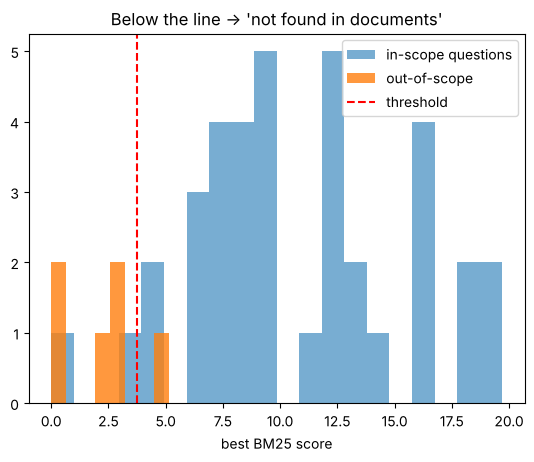

 2.40  What is the CEO's salary?
 3.20  How do I apply for a job at Kaveri Retail?
 0.00  What is the weather in Mumbai today?
 3.20  Does Kaveri Retail sell groceries?
 5.15  What is the company share price?
 0.00  Who won the cricket world cup?


In [8]:
from src.rag.rag_system import BM25Retriever
from src.rag.evaluate_rag import QUESTIONS, OUT_OF_SCOPE
gate = BM25Retriever().fit(texts)
rin = [gate.scores(expand_query(q)).max() for q, *_ in QUESTIONS]
rout = [gate.scores(expand_query(q)).max() for q in OUT_OF_SCOPE]
plt.hist(rin, bins=20, alpha=.6, label="in-scope questions"); plt.hist(rout, bins=8, alpha=.8, label="out-of-scope")
plt.axvline(r["selected"]["abstain_threshold"], c="r", ls="--", label="threshold")
plt.legend(); plt.xlabel("best BM25 score"); plt.title("Below the line -> 'not found in documents'"); plt.show()
for q, s in zip(OUT_OF_SCOPE, rout): print(f"{s:5.2f}  {q}")

"Company share price" galti se answer ho jaata hai — "price" word "Price Match" section se match karta hai.
Keyword-based gate meaning nahi samajhta. LLM ke saath ye check behtar hota hai (prompt mein NOT_FOUND rule).

## 6. Khud poochiye

In [9]:
from src.rag.rag_system import RAG
rag = RAG()
for q in ["refund card mein kitne din mein aayega", "Who must approve a refund of Rs 25,000?",
          "How many customers are at high churn risk?", "What is the CEO's salary?"]:
    a = rag.ask(q, use_llm=False); print(f"Q: {q}\nA: {a['answer']}\n")

Q: refund card mein kitne din mein aayega
A: After the returned item passes the quality check, the refund is started within 48 hours. Refunds to the Kaveri Wallet are credited within 24 hours of approval. Refunds to UPI are credited within 2 to 3 business days. Refunds to credit or debit cards take 5 to 7 business days, depending on the bank. Cash on Delivery orders are refunded to the Kaveri Wallet or to a bank account given by the customer.  [Returns and Refund Policy, 4. Refund Timelines, p.1]

Q: Who must approve a refund of Rs 25,000?
A: Level 1 agents can approve refunds up to Rs 2,000. Level 2 specialists can approve up to Rs 10,000. Refunds above Rs 10,000 need Support Manager approval, and above Rs 50,000 need Finance Head approval.  [Customer Support SOP, 5. Refund Approval Limits, p.1]

Q: How many customers are at high churn risk?
A: The churn model flags 213 customers as High risk, with Rs 86.1 lakh of annual revenue at risk. The strongest warning signs are recent negative

## 7. LLM ke saath (optional)
`rag_system.claude_answer()` wahi chunks Claude ko deta hai, strict instruction ke saath: *sirf in sources
se jawab do, numbers exact likho, source batao, nahi mile toh NOT_FOUND*. Enable karne ke liye:
```
pip install anthropic
set ANTHROPIC_API_KEY=your-key        (Windows)
python -m src.rag.ask
```
Bina key ke system extractive mode mein chalta hai (jo upar dekha). LLM wala path is project mein test nahi
hua hai (key nahi thi) — enable karne ke baad `evaluate_rag.py` ko `use_llm=True` se chala kar zaroor naapiye.

## Takeaways
- RAG = **retrieve + ground + cite + abstain**. Citation se user khud check kar sakta hai.
- **Test set pehle.** Usi se pata chala ki problem retrieval mein nahi, answer step mein thi.
- Chhote, saaf documents par simple TF-IDF/BM25 hi kaafi hai; methods ka fark noise jitna tha.
- Paraphrase aur "share price" jaisi galtiyan keyword search ki seema hain → next upgrade: embeddings + LLM.
- Apne PDFs `data/docs/` mein daaliye, `python -m src.rag.evaluate_rag` mein apne sawal jodiye.